In [1]:
from scipy.io import loadmat
import pandas as pd
import numpy as np
import h5py
import os
import matplotlib.pyplot as plt
import seaborn as sns


Clinical variables

In [2]:
clinical = loadmat("./data/scores_EP_organised.mat") #UNREADABLE

In [15]:
panss_AP = clinical["panss_AP"][0]
panss_NAP = clinical["panss_NAP"][0]
ymrs_AP = clinical["ymrs_AP"][0]
ymrs_NAP = clinical["ymrs_NAP"][0]

# Cleaning
panss_AP = panss_AP.astype(float) 
panss_AP[panss_AP == 0] = np.nan

panss_NAP = panss_NAP.astype(float) 
panss_NAP[panss_NAP == 0] = np.nan

In [17]:
# save it
np.savez_compressed(
    './data/HCP_early_psychosis_clinical_scores.npz',
    panss_AP=panss_AP,
    panss_NAP=panss_NAP,
    ymrs_AP=ymrs_AP,
    ymrs_NAP=ymrs_NAP,
)

SC data

In [2]:
file_path = "./data/SC_schaefer100_17Networks_32fold_groupconnectome_2mm_symm.mat"

with h5py.File(file_path, 'r') as f:
    # Load the connectivity matrix
    # We use .T because MATLAB is column-major and Python is row-major
    sc = f['SC'][()].T
    
    # Load the distance matrix
    sc_d = f['SC_D'][()].T

print(f"SC Matrix Shape: {sc.shape}")
print(f"SC_D Matrix Shape: {sc_d.shape}")

SC Matrix Shape: (100, 100)
SC_D Matrix Shape: (100, 100)


In [ ]:
# save it
np.savez_compressed("./data/Structural_Connectomes.npz", 
                    SC=sc, 
                    SC_D=sc_d)

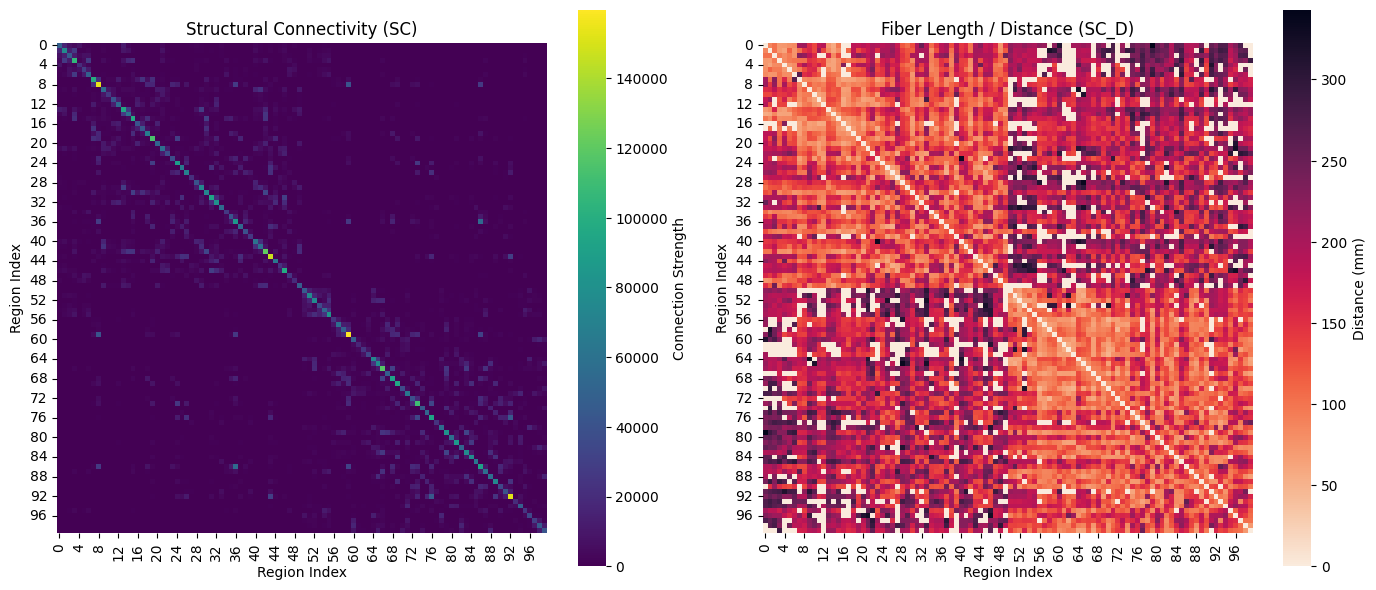

In [3]:
# Create a figure with two side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# 1. Plot Structural Connectivity (SC)
# We use a Log norm because SC values often vary drastically
sns.heatmap(sc, ax=ax[0], cmap='viridis', square=True, cbar_kws={'label': 'Connection Strength'})
ax[0].set_title('Structural Connectivity (SC)')
ax[0].set_xlabel('Region Index')
ax[0].set_ylabel('Region Index')

# 2. Plot Distance Matrix (SC_D)
sns.heatmap(sc_d, ax=ax[1], cmap='rocket_r', square=True, cbar_kws={'label': 'Distance (mm)'})
ax[1].set_title('Fiber Length / Distance (SC_D)')
ax[1].set_xlabel('Region Index')
ax[1].set_ylabel('Region Index')

plt.tight_layout()
plt.show()

fmri data

In [4]:
# Load the file
data = loadmat('./data/HCP_early_psychosis_data_schaefer100.mat')

# 1. Clean the Filter/Frequency variables
# .item() is used for single values, .squeeze() for arrays
flp = data['flp'].item() if data['flp'].size == 1 else data['flp'].squeeze()
fhi = data['fhi'].item() if data['fhi'].size == 1 else data['fhi'].squeeze()

# 2. Extract and Squeeze the Time Series groups
# We'll store them in a dictionary for easy access
timeseries = {}
groups = ['AP', 'HC', 'NAP']

for g in groups:
    key = f'ts_subject_{g}'
    if key in data:
        # Squeeze removes the (1, N) or (N, 1) nesting common in SciPy
        raw_ts = data[key].squeeze()
        
        # If the result is an array of objects (Cell Array), 
        # we further squeeze the internal arrays
        if raw_ts.dtype == object:
            timeseries[g] = [subj.squeeze() for subj in raw_ts]
        else:
            timeseries[g] = raw_ts

# 3. Access your variables directly
ts_ap = timeseries.get('AP')
ts_hc = timeseries.get('HC')
ts_nap = timeseries.get('NAP')

print(f"Filter range: {flp} - {fhi} Hz")
print(f"Group HC contains {len(ts_hc)} subjects.")
print(f"Group AP contains {len(ts_ap)} subjects.")
print(f"Group NAP contains {len(ts_nap)} subjects.")

print(
np.shape(ts_ap),
np.shape(ts_hc),
np.shape(ts_nap)
)

Filter range: 0.008 - 0.08 Hz
Group HC contains 48 subjects.
Group AP contains 25 subjects.
Group NAP contains 76 subjects.
(25, 100, 1581) (48, 100, 1581) (76, 100, 1581)


In [84]:
# save it
np.savez_compressed(
    './data/HCP_early_psychosis_timeseries_cleaned.npz',
    flp=flp,
    fhi=fhi,
    ts_ap=ts_ap,
    ts_hc=ts_hc,
    ts_nap=ts_nap
)


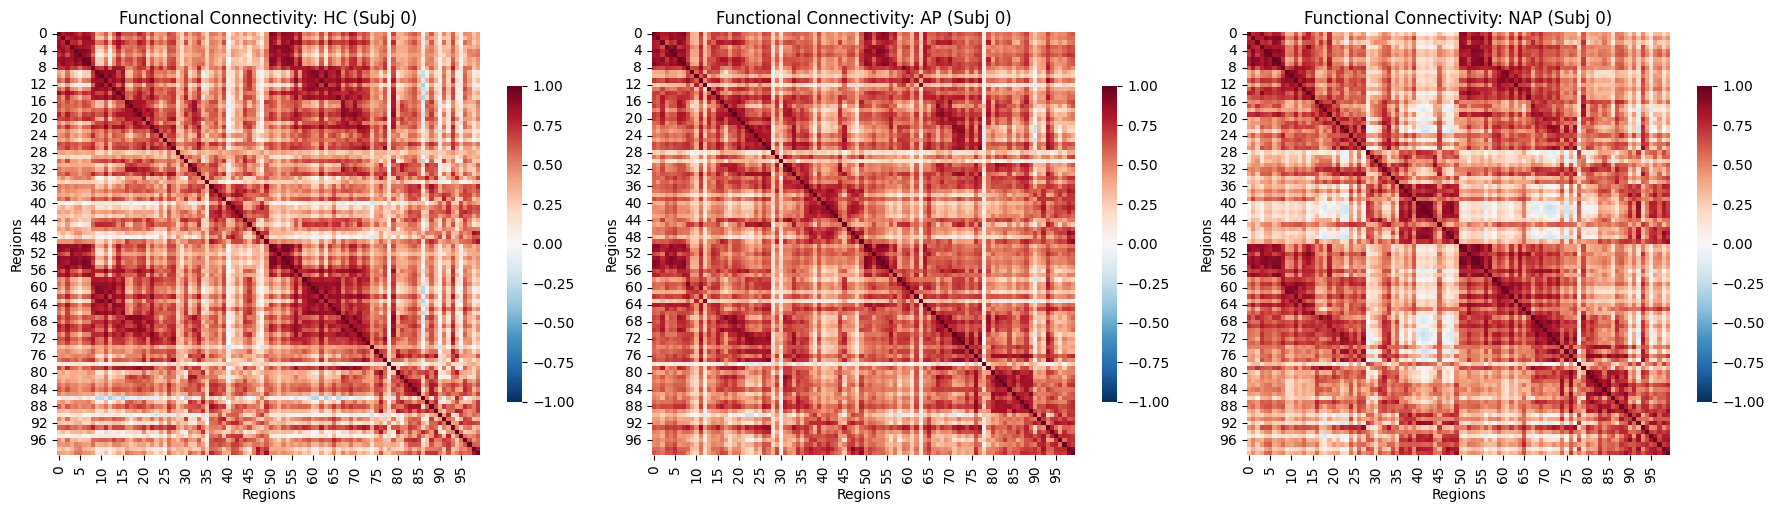

In [5]:
# Function to calculate FC matrix for a single subject
def calculate_fc(ts_data):
    # np.corrcoef calculates correlation between rows (regions)
    fc_matrix = np.corrcoef(ts_data)
    return fc_matrix


# 1. Calculate FC for the first subject of each group
ts_subject_AP = ts_ap[0]
ts_subject_HC = ts_hc[0]
ts_subject_NAP = ts_nap[1]

fc_ap = calculate_fc(ts_subject_AP)
fc_hc = calculate_fc(ts_subject_HC)
fc_nap = calculate_fc(ts_subject_NAP)

# 2. Plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
groups = [('HC', fc_hc), ('AP', fc_ap), ('NAP', fc_nap)]

for i, (name, matrix) in enumerate(groups):
    # We use a diverging colormap (RdBu_r) because correlations range from -1 to 1
    sns.heatmap(matrix, ax=axes[i], cmap='RdBu_r', center=0, vmin=-1, vmax=1, 
                square=True, cbar_kws={'shrink': .7})
    axes[i].set_title(f'Functional Connectivity: {name} (Subj 0)')
    axes[i].set_xlabel('Regions')
    axes[i].set_ylabel('Regions')

plt.tight_layout()
plt.show()

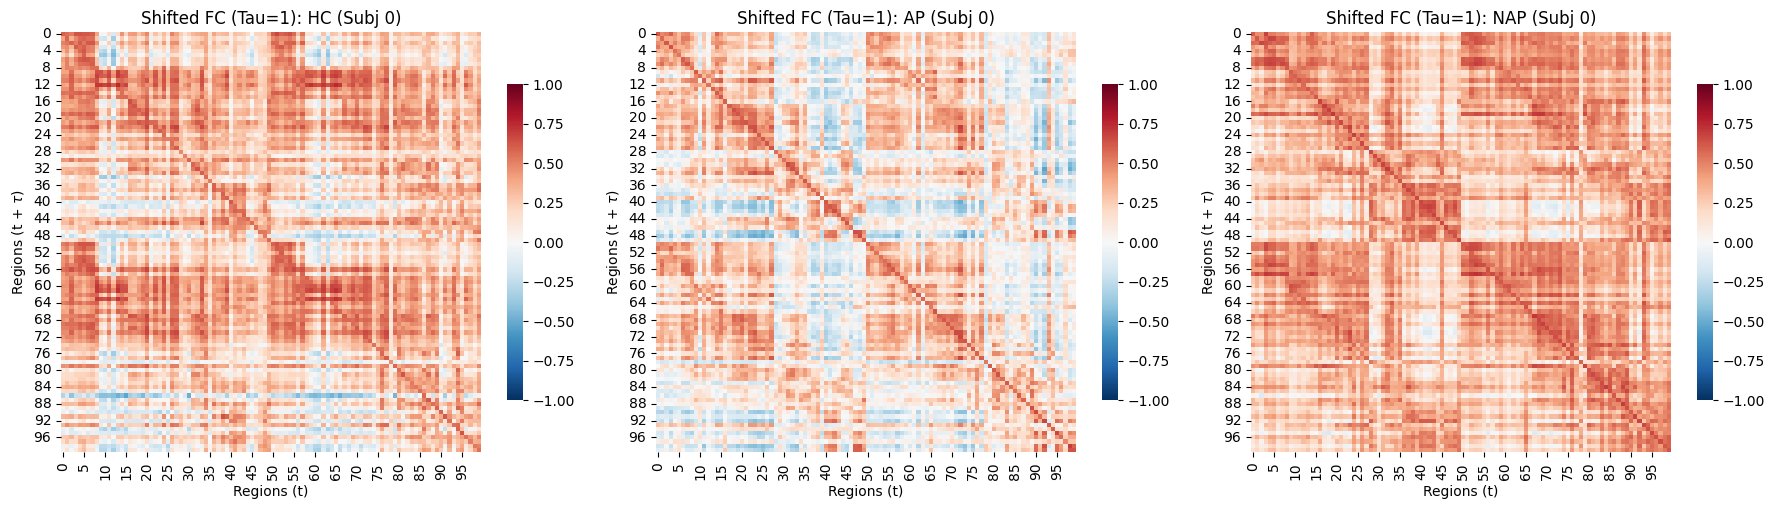

In [7]:

def calculate_fs(ts_data, tau=1):
    """
    Calculates time-shifted Functional Connectivity (FS) matrix.
    tau represents the lag/shift in timepoints (usually 1 TR).
    """
    T = ts_data.shape[1]
    
    # 1. Mean-center the time series
    ts_c = ts_data - np.mean(ts_data, axis=1, keepdims=True)
    
    # 2. Calculate the shifted covariance matrix
    # We multiply the signal up to (T-tau) with the signal shifted by tau
    cov_shifted = np.dot(ts_c[:, :-tau], ts_c[:, tau:].T) / T
    
    # 3. Calculate the standard deviations of the original time series
    # ddof=1 computes the sample standard deviation
    std_emp = np.std(ts_data, axis=1, ddof=1)
    
    # 4. Normalize to convert shifted covariance to shifted correlation (FS)
    fs_matrix = cov_shifted / np.outer(std_emp, std_emp)
    
    return fs_matrix

# Get the first subject's time series for each group
ts_subject_AP = ts_ap[1]
ts_subject_HC = ts_hc[0]
ts_subject_NAP = ts_nap[1]

# Calculate FS with a lag of 1
fs_ap = calculate_fs(ts_subject_AP, tau=5)
fs_hc = calculate_fs(ts_subject_HC, tau=5)
fs_nap = calculate_fs(ts_subject_NAP, tau=5)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
groups = [('HC', fs_hc), ('AP', fs_ap), ('NAP', fs_nap)]

for i, (name, matrix) in enumerate(groups):
    # We keep RdBu_r for diverging correlations
    # FS values are usually much smaller than standard FC, so you might need 
    # to lower vmin and vmax if the plot looks too faded (e.g., vmin=-0.5, vmax=0.5)
    sns.heatmap(matrix, ax=axes[i], cmap='RdBu_r', center=0, vmin=-1, vmax=1, 
                square=True, cbar_kws={'shrink': .7})
    axes[i].set_title(f'Shifted FC (Tau=1): {name} (Subj 0)')
    axes[i].set_xlabel('Regions (t)')
    axes[i].set_ylabel('Regions (t + $\\tau$)')

plt.tight_layout()
plt.show()

It seems the data is already z-scored and well parcellated